In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
import kagglehub

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split, Subset

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import (precision_score,recall_score,f1_score,classification_report,confusion_matrix)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import onnxruntime as ort

import cv2
import base64
from IPython.display import display, Javascript
from google.colab.output import eval_js

In [7]:
path = kagglehub.dataset_download("msambare/fer2013")

print("Downloaded to:", path)

Using Colab cache for faster access to the 'fer2013' dataset.
Downloaded to: /kaggle/input/fer2013


In [8]:
TRAIN_DIR = os.path.join(path, "train")
TEST_DIR = os.path.join(path, "test")

print("Train folder:", TRAIN_DIR)
print("Test folder:", TEST_DIR)

Train folder: /kaggle/input/fer2013/train
Test folder: /kaggle/input/fer2013/test


In [9]:
raw_train = datasets.ImageFolder(TRAIN_DIR)
raw_test = datasets.ImageFolder(TEST_DIR)

classes = raw_train.classes
NUM_CLASSES = len(classes)

print("Classes:", classes)
print("Number of classes:", NUM_CLASSES)
print("Training images:", len(raw_train))
print("Test images:", len(raw_test))

Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Number of classes: 7
Training images: 28709
Test images: 7178


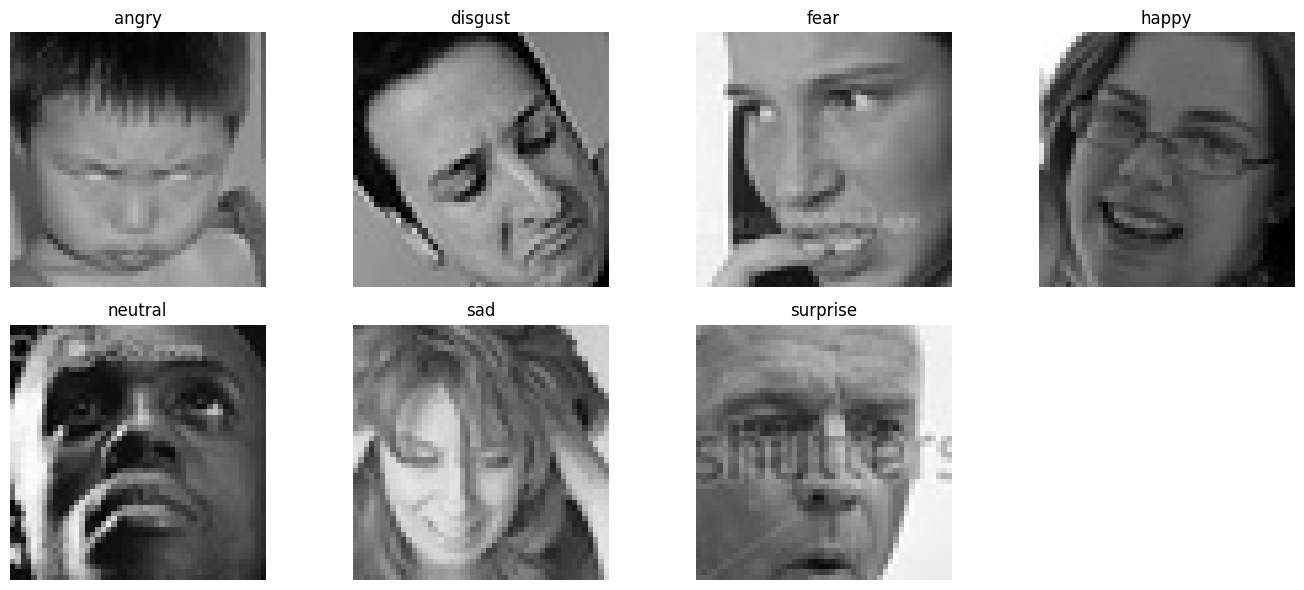

In [10]:
plt.figure(figsize=(14, 6))

for i in range(NUM_CLASSES):
    index = raw_train.targets.index(i)
    image, label = raw_train[index]

    plt.subplot(2, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(classes[label])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [11]:
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()
])


In [12]:
train_size = int(0.8 * len(raw_train))
val_size = len(raw_train) - train_size

train_data, val_data = random_split(
    raw_train,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(raw_test))


Training images: 22967
Validation images: 5742
Test images: 7178


In [13]:
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
val_dataset = datasets.ImageFolder(TRAIN_DIR, transform=test_transform)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transform)

train_data = Subset(train_dataset, train_data.indices)
val_data = Subset(val_dataset, val_data.indices)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_dataset))


Training images: 22967
Validation images: 5742
Test images: 7178


In [14]:
batch_size = 64

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Train batches: 359
Validation batches: 90
Test batches: 113


In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(64 * 12 * 12, 128),
    nn.ReLU(),
    nn.Linear(128, NUM_CLASSES)
).to(device)

print(model)

Device: cuda
Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=9216, out_features=128, bias=True)
  (8): ReLU()
  (9): Linear(in_features=128, out_features=7, bias=True)
)


In [16]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Loss Function:", criterion)
print("Optimizer:", optimizer)


Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [17]:

epochs = 3
print("Training started...\n")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, answers in train_loader:
        images = images.to(device)
        answers = answers.to(device)

        scores = model(images)
        loss = criterion(scores, answers)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs} - Loss: {running_loss/len(train_loader):.4f}")

print("\nDone training!")


Training started...

Epoch 1/3 - Loss: 1.7238
Epoch 2/3 - Loss: 1.5921
Epoch 3/3 - Loss: 1.4932

Done training!


In [18]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, answers in val_loader:
        images = images.to(device)
        answers = answers.to(device)

        scores = model(images)
        _, predictions = scores.max(1)

        correct += (predictions == answers).sum().item()
        total += answers.size(0)

print(f"Correct: {correct} / {total}")
print(f"Validation Accuracy: {correct/total*100:.2f}%")


Correct: 2574 / 5742
Validation Accuracy: 44.83%


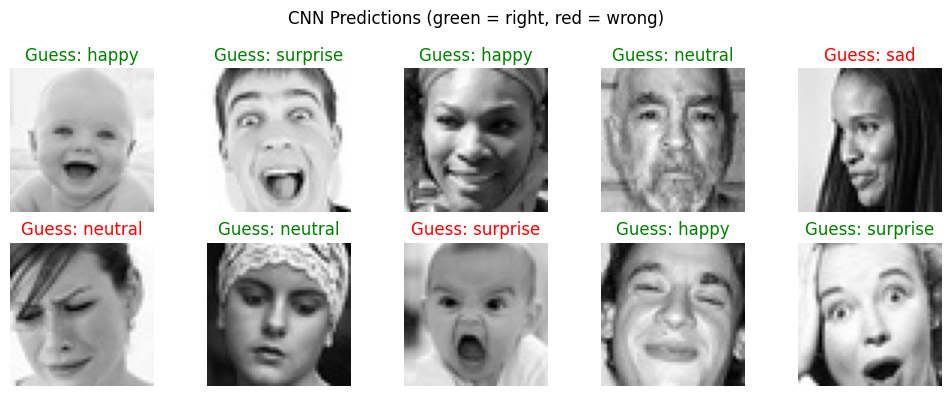

In [19]:
images, answers = next(iter(val_loader))
images_gpu = images.to(device)

model.eval()
with torch.no_grad():
    scores = model(images_gpu)

_, predictions = scores.max(1)
predictions = predictions.cpu()

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    color = 'green' if predictions[i] == answers[i] else 'red'
    plt.title(f"Guess: {classes[predictions[i].item()]}", color=color)
    plt.axis('off')

plt.suptitle("CNN Predictions (green = right, red = wrong)")
plt.tight_layout()
plt.show()

##Transfer Learning

#ResNet18

In [20]:
counts = np.bincount(raw_train.targets)

for i in range(NUM_CLASSES):
    print(f"{classes[i]}: {counts[i]}")


angry: 3995
disgust: 436
fear: 4097
happy: 7215
neutral: 4965
sad: 4830
surprise: 3171


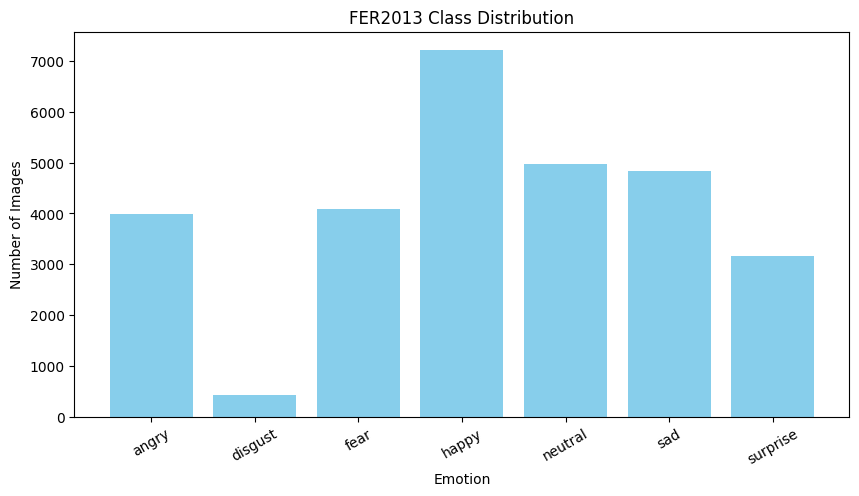

In [21]:
# Plot class distribution
plt.figure(figsize=(10, 5))
plt.bar(classes, counts, color="skyblue")

plt.title("FER2013 Class Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)

plt.show()


In [22]:
resnet_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

resnet_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [23]:
resnet_train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=resnet_train_transform)
resnet_val_dataset = datasets.ImageFolder(TRAIN_DIR, transform=resnet_test_transform)
resnet_test_dataset = datasets.ImageFolder(TEST_DIR, transform=resnet_test_transform)

resnet_train_data = Subset(resnet_train_dataset, train_data.indices)
resnet_val_data = Subset(resnet_val_dataset, val_data.indices)

print("Training images:", len(resnet_train_data))
print("Validation images:", len(resnet_val_data))
print("Test images:", len(resnet_test_dataset))


Training images: 22967
Validation images: 5742
Test images: 7178


In [24]:
resnet_train_loader = DataLoader(resnet_train_data, batch_size=64, shuffle=True)
resnet_val_loader = DataLoader(resnet_val_data, batch_size=64, shuffle=False)
resnet_test_loader = DataLoader(resnet_test_dataset, batch_size=64, shuffle=False)

print("Train batches:", len(resnet_train_loader))
print("Validation batches:", len(resnet_val_loader))
print("Test batches:", len(resnet_test_loader))

Train batches: 359
Validation batches: 90
Test batches: 113


In [25]:
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for param in resnet.parameters():
    param.requires_grad = False

resnet.fc = nn.Linear(resnet.fc.in_features, NUM_CLASSES)

resnet = resnet.to(device)

print(resnet.fc)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]


Linear(in_features=512, out_features=7, bias=True)


In [26]:
resnet_criterion = nn.CrossEntropyLoss()
resnet_optimizer = optim.Adam(resnet.fc.parameters(), lr=0.001)

In [27]:
epochs = 3
print("Training ResNet18...\n")

for epoch in range(epochs):
    resnet.eval()
    running_loss = 0.0

    for images, answers in resnet_train_loader:
        images = images.to(device)
        answers = answers.to(device)

        scores = resnet(images)
        loss = resnet_criterion(scores, answers)

        resnet_optimizer.zero_grad()
        loss.backward()
        resnet_optimizer.step()

        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs} - Loss: {running_loss/len(resnet_train_loader):.4f}")

print("\nDone training!")


Training ResNet18...

Epoch 1/3 - Loss: 1.6187
Epoch 2/3 - Loss: 1.4940
Epoch 3/3 - Loss: 1.4557

Done training!


In [28]:
resnet.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, answers in resnet_val_loader:
        images = images.to(device)
        answers = answers.to(device)

        scores = resnet(images)
        _, predictions = scores.max(1)

        correct += (predictions == answers).sum().item()
        total += answers.size(0)

resnet_val_acc = correct / total * 100

print(f"Correct: {correct} / {total}")
print(f"Validation Accuracy: {resnet_val_acc:.2f}%")


Correct: 2569 / 5742
Validation Accuracy: 44.74%


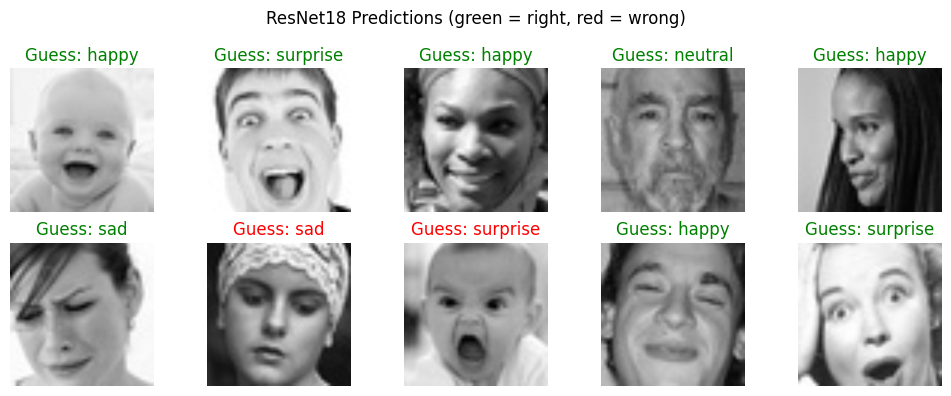

In [29]:
images, answers = next(iter(resnet_val_loader))
images_gpu = images.to(device)

resnet.eval()
with torch.no_grad():
    scores = resnet(images_gpu)

_, predictions = scores.max(1)
predictions = predictions.cpu()

# Denormalize images for display
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = images[i] * std + mean
    plt.imshow(image.permute(1, 2, 0).clamp(0, 1))

    color = "green" if predictions[i] == answers[i] else "red"
    plt.title(f"Guess: {classes[predictions[i].item()]}", color=color)
    plt.axis("off")

plt.suptitle("ResNet18 Predictions (green = right, red = wrong)")
plt.tight_layout()
plt.show()


In [30]:
# Save Transfer Learning model
torch.save(resnet.state_dict(), "resnet_transfer.pth")

print("Transfer Learning model saved!")


Transfer Learning model saved!


#Fine-Tuning

In [31]:
resnet_fine = models.resnet18(weights=None)
resnet_fine.fc = nn.Linear(resnet_fine.fc.in_features, NUM_CLASSES)

resnet_fine.load_state_dict(torch.load("resnet_transfer.pth", map_location=device))
resnet_fine = resnet_fine.to(device)


In [32]:
# Freeze all layers
for param in resnet_fine.parameters():
    param.requires_grad = False

# Unfreeze the last layers
for param in resnet_fine.layer3.parameters():
    param.requires_grad = True

for param in resnet_fine.layer4.parameters():
    param.requires_grad = True

for param in resnet_fine.fc.parameters():
    param.requires_grad = True

In [33]:
criterion_fine = nn.CrossEntropyLoss()

optimizer_fine = optim.Adam(
    list(resnet_fine.layer3.parameters()) +
    list(resnet_fine.layer4.parameters()) +
    list(resnet_fine.fc.parameters()),
    lr=0.00005
)

In [34]:
epochs_fine = 4
print("Training Fine-Tuning ResNet18...\n")

for epoch in range(epochs_fine):
    resnet_fine.eval()
    running_loss = 0.0

    for images, answers in resnet_train_loader:
        images = images.to(device)
        answers = answers.to(device)

        scores = resnet_fine(images)
        loss = criterion_fine(scores, answers)

        optimizer_fine.zero_grad()
        loss.backward()
        optimizer_fine.step()

        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs_fine} - Loss: {running_loss/len(resnet_train_loader):.4f}")

print("\nDone training!")


Training Fine-Tuning ResNet18...

Epoch 1/4 - Loss: 1.2405
Epoch 2/4 - Loss: 1.0554
Epoch 3/4 - Loss: 0.9622
Epoch 4/4 - Loss: 0.9017

Done training!


In [35]:
resnet_fine.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, answers in resnet_val_loader:
        images = images.to(device)
        answers = answers.to(device)

        scores = resnet_fine(images)
        _, predictions = scores.max(1)

        correct += (predictions == answers).sum().item()
        total += answers.size(0)

fine_val_acc = correct / total * 100

print(f"Correct: {correct} / {total}")
print(f"Validation Accuracy: {fine_val_acc:.2f}%")


Correct: 3553 / 5742
Validation Accuracy: 61.88%


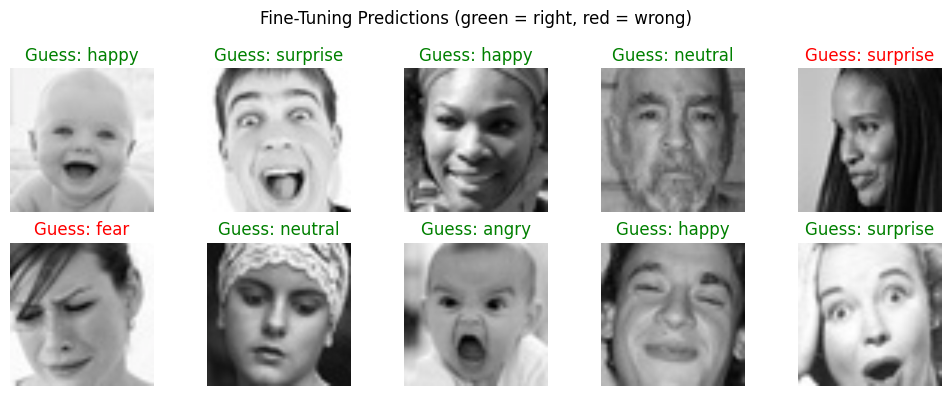

In [36]:

images, answers = next(iter(resnet_val_loader))
images_gpu = images.to(device)

resnet_fine.eval()
with torch.no_grad():
    scores = resnet_fine(images_gpu)

_, predictions = scores.max(1)
predictions = predictions.cpu()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = images[i] * std + mean
    plt.imshow(image.permute(1, 2, 0).clamp(0, 1))

    color = "green" if predictions[i] == answers[i] else "red"
    plt.title(f"Guess: {classes[predictions[i].item()]}", color=color)
    plt.axis("off")

plt.suptitle("Fine-Tuning Predictions (green = right, red = wrong)")
plt.tight_layout()
plt.show()


In [37]:
torch.save(resnet_fine.state_dict(), "resnet_fine_final.pth")
print("Fine-Tuning model saved!")

Fine-Tuning model saved!


#Evaluation & Comparison

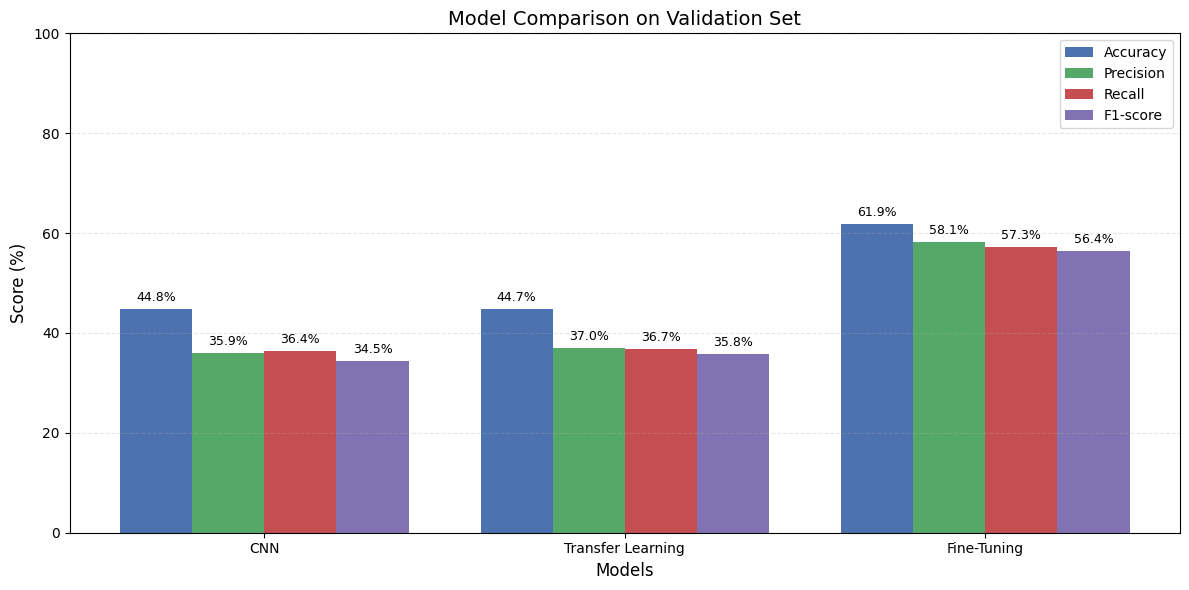

In [38]:
models = ["CNN", "Transfer Learning", "Fine-Tuning"]
networks = [model, resnet, resnet_fine]
loaders = [val_loader, resnet_val_loader, resnet_val_loader]

accuracy = []
precision = []
recall = []
f1_scores = []

# Evaluate all models
for network, loader in zip(networks, loaders):
    network.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = network(images)
            _, predicted = outputs.max(1)

            y_true.extend(labels.numpy())
            y_pred.extend(predicted.cpu().numpy())

    accuracy.append(accuracy_score(y_true, y_pred) * 100)
    precision.append(precision_score(y_true, y_pred, average="macro", zero_division=0) * 100)
    recall.append(recall_score(y_true, y_pred, average="macro", zero_division=0) * 100)
    f1_scores.append(f1_score(y_true, y_pred, average="macro", zero_division=0) * 100)

# Plot comparison
x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(12, 6))

bars1 = plt.bar(x - 1.5*width, accuracy, width, label="Accuracy", color="#4C72B0")
bars2 = plt.bar(x - 0.5*width, precision, width, label="Precision", color="#55A868")
bars3 = plt.bar(x + 0.5*width, recall, width, label="Recall", color="#C44E52")
bars4 = plt.bar(x + 1.5*width, f1_scores, width, label="F1-score", color="#8172B3")

plt.title("Model Comparison on Validation Set", fontsize=14)
plt.xlabel("Models", fontsize=12)
plt.ylabel("Score (%)", fontsize=12)

plt.xticks(x, models)
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Show values above bars
for bars in [bars1, bars2, bars3, bars4]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 1,
            f"{height:.1f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()
plt.show()


#Optimization & Deployment

In [39]:
#!pip install -q onnx onnxscript onnxruntime

In [40]:
# Export Fine-Tuning ResNet18 to ONNX
resnet_fine.eval()

dummy_input = torch.randn(1, 3, 224, 224).to(device)

torch.onnx.export(
    resnet_fine,
    dummy_input,
    "resnet_fine.onnx",
    input_names=["input"],
    output_names=["output"],
    opset_version=18,
    dynamo=True
)

print("ResNet18 exported to ONNX!")

[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ResNet18 exported to ONNX!


In [41]:
# Load face detector
face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

print("Face Detector Loaded:", not face_detector.empty())


Face Detector Loaded: True


In [42]:
# Load ONNX model
session = ort.InferenceSession(
    "resnet_fine.onnx",
    providers=["CPUExecutionProvider"]
)

# Predict facial expression
def predict_emotion(face):
    face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
    face = cv2.resize(face, (224, 224))

    face = face.astype(np.float32) / 255.0
    face = (face - [0.485, 0.456, 0.406]) / [0.229, 0.224, 0.225]
    face = face.astype(np.float32)

    face = np.transpose(face, (2, 0, 1))
    face = np.expand_dims(face, axis=0)

    outputs = session.run(None, {"input": face})
    prediction = np.argmax(outputs[0])

    return classes[prediction]

print("Emotion Model Loaded!")


Emotion Model Loaded!


In [43]:
display(Javascript("""
async function startCamera() {
    const old = document.getElementById('emotion-camera');
    if (old) old.remove();

    if (window.emotionStream) {
        window.emotionStream.getTracks().forEach(t => t.stop());
    }

    const container = document.createElement('div');
    container.id = 'emotion-camera';
    container.style.position = 'relative';
    container.style.width = '480px';

    const video = document.createElement('video');
    video.width = 480;
    video.height = 360;
    video.autoplay = true;
    video.playsInline = true;

    const canvas = document.createElement('canvas');
    canvas.width = 480;
    canvas.height = 360;
    canvas.style.position = 'absolute';
    canvas.style.left = '0';
    canvas.style.top = '0';
    canvas.style.pointerEvents = 'none';

    const button = document.createElement('button');
    button.innerText = 'Stop Camera';

    container.appendChild(video);
    container.appendChild(canvas);
    document.body.appendChild(container);
    document.body.appendChild(button);

    const stream = await navigator.mediaDevices.getUserMedia({
        video: {width: 480, height: 360},
        audio: false
    });

    video.srcObject = stream;
    await video.play();

    window.emotionVideo = video;
    window.emotionStream = stream;
    window.emotionCanvas = canvas;
    window.emotionRunning = true;

    button.onclick = () => {
        window.emotionRunning = false;
        stream.getTracks().forEach(t => t.stop());
        canvas.getContext('2d').clearRect(0, 0, 480, 360);
        button.innerText = 'Camera Stopped';
    };
}

function getFrame() {
    if (!window.emotionRunning) return null;

    const canvas = document.createElement('canvas');
    canvas.width = 320;
    canvas.height = 240;

    canvas.getContext('2d').drawImage(
        window.emotionVideo, 0, 0, 320, 240
    );

    return canvas.toDataURL('image/jpeg', 0.5);
}

function drawPrediction(x, y, w, h, emotion) {
    if (!window.emotionRunning) return;

    const canvas = window.emotionCanvas;
    const ctx = canvas.getContext('2d');

    ctx.clearRect(0, 0, canvas.width, canvas.height);

    if (!emotion) return;

    // Scale coordinates from 320x240 to 480x360
    x *= 1.5;
    y *= 1.5;
    w *= 1.5;
    h *= 1.5;

    ctx.strokeStyle = '#00FF00';
    ctx.lineWidth = 3;
    ctx.strokeRect(x, y, w, h);

    ctx.font = 'bold 18px Arial';
    const textWidth = ctx.measureText(emotion).width;
    const labelY = Math.max(25, y);

    ctx.fillStyle = '#00FF00';
    ctx.fillRect(x, labelY - 25, textWidth + 14, 25);

    ctx.fillStyle = '#000000';
    ctx.fillText(emotion, x + 7, labelY - 6);
}
"""))

eval_js("startCamera()")

while True:
    frame_data = eval_js("getFrame()")

    if frame_data is None:
        break

    image_bytes = base64.b64decode(frame_data.split(",")[1])
    frame = cv2.imdecode(
        np.frombuffer(image_bytes, np.uint8),
        cv2.IMREAD_COLOR
    )

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    faces = face_detector.detectMultiScale(
        gray, scaleFactor=1.2, minNeighbors=5
    )

    if len(faces) > 0:
        x, y, w, h = faces[0]
        face = frame[y:y+h, x:x+w]

        emotion = predict_emotion(face)

        eval_js(f"drawPrediction({x}, {y}, {w}, {h}, {emotion!r})")
    else:
        eval_js("drawPrediction(0, 0, 0, 0, '')")

    # Reduce processing frequency
    import time
    time.sleep(0.3)


<IPython.core.display.Javascript object>

In [44]:
from google.colab import files

files.download("resnet_fine.onnx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

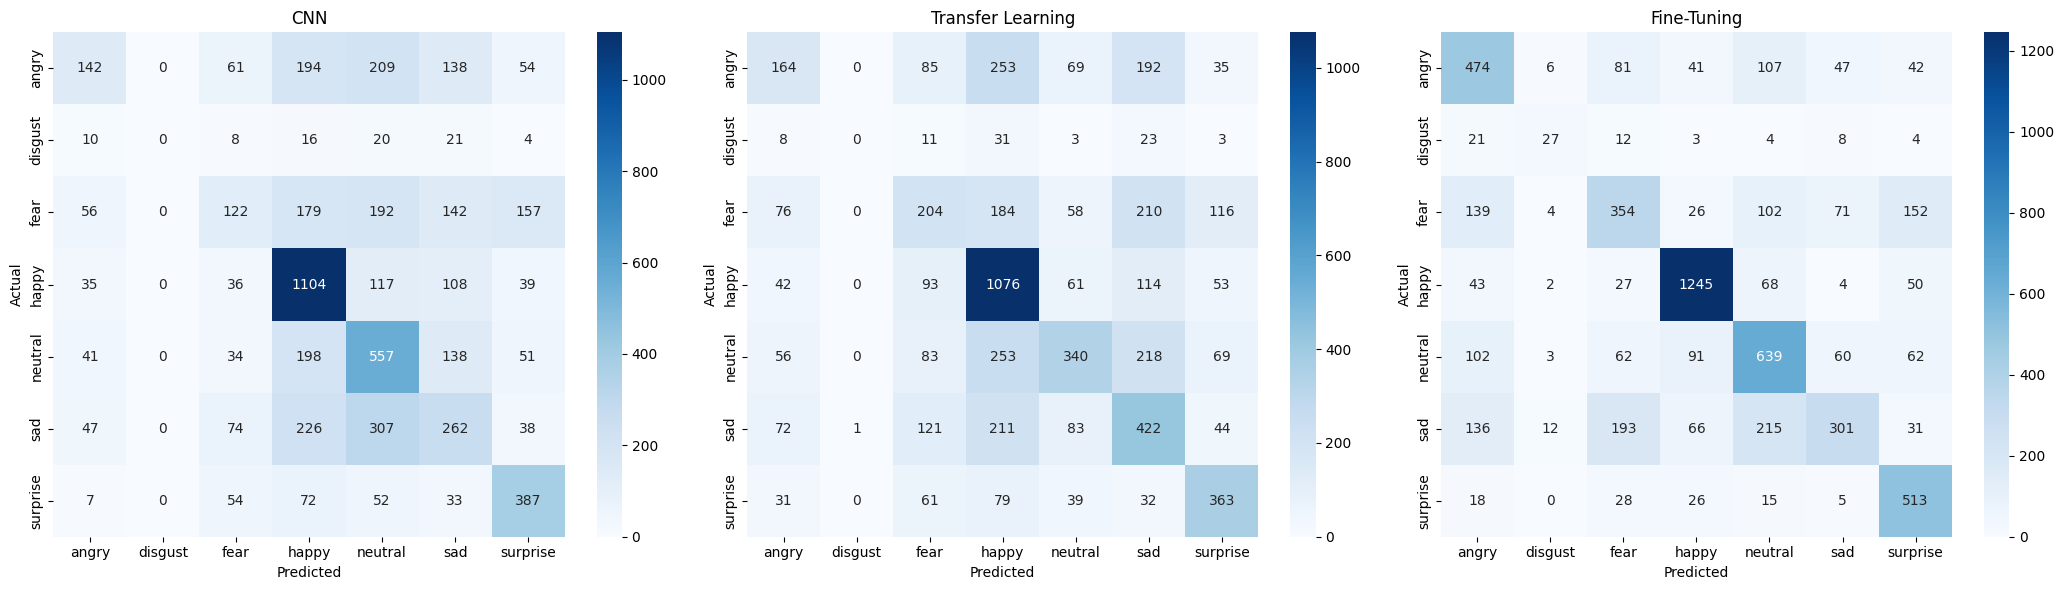

In [45]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

models = [model, resnet, resnet_fine]
loaders = [val_loader, resnet_val_loader, resnet_val_loader]
names = ["CNN", "Transfer Learning", "Fine-Tuning"]

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

for i in range(3):
    models[i].eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in loaders[i]:
            images = images.to(device)
            outputs = models[i](images)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    cm = confusion_matrix(y_true, y_pred, labels=range(len(classes)))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        ax=axes[i]
    )

    axes[i].set_title(names[i])
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()


Saving WhatsApp Image 2026-10-14 at 10.32.40 AM.jpeg to WhatsApp Image 2026-10-14 at 10.32.40 AM.jpeg


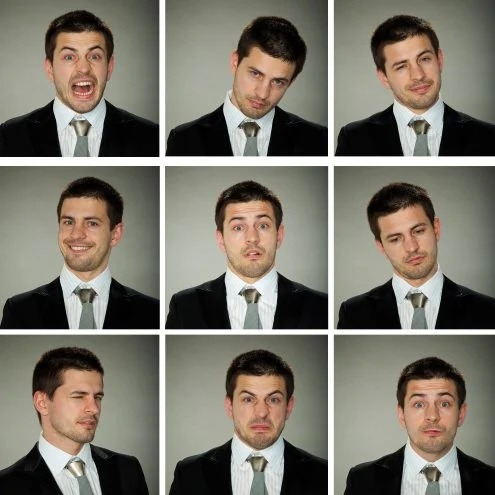

In [46]:

from google.colab import files
from PIL import Image

uploaded = files.upload()

image = Image.open(next(iter(uploaded))).convert("RGB")
display(image)


Faces Detected: 9


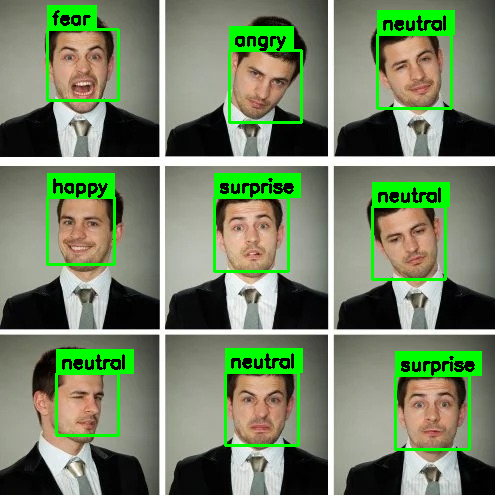

In [48]:
# Face Detection & Emotion Prediction

from google.colab.patches import cv2_imshow

img = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

faces = face_detector.detectMultiScale(
    gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)
)

resnet_fine.eval()

for (x, y, w, h) in faces:
    face = img[y:y+h, x:x+w]
    face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
    face = Image.fromarray(face)

    face_tensor = resnet_test_transform(face).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = resnet_fine(face_tensor)
        prediction = outputs.argmax(dim=1).item()

    emotion = classes[prediction]

    # Draw face box
    cv2.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 2)

    # Draw emotion label
    font = cv2.FONT_HERSHEY_SIMPLEX
    text_size = cv2.getTextSize(emotion, font, 0.6, 2)[0]
    label_y = max(y, text_size[1] + 10)

    cv2.rectangle(
        img,
        (x, label_y - text_size[1] - 10),
        (x + text_size[0] + 10, label_y),
        (0, 255, 0),
        -1
    )

    cv2.putText(
        img, emotion, (x + 5, label_y - 5),
        font, 0.6, (0, 0, 0), 2
    )

print("Faces Detected:", len(faces))
cv2_imshow(img)
